In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("centrifuge line datasets.parquet")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
pf = pq.ParquetFile(DATA_PATH)
display(pd.DataFrame({"column": pf.schema_arrow.names,
                      "parquet_type": [str(f.type) for f in pf.schema_arrow]}))
print(f"Rows: {pf.metadata.num_rows:,}; file size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")
df = pq.read_table(DATA_PATH).to_pandas()

,column,parquet_type
0,date,"timestamp[ns, tz=UTC]"
1,Motor DE_Z Short Wave High Frequency,list<element: double>
2,Motor DE_Z Long Wave High Frequency,list<element: double>
3,Motor DE_X Short Wave Low Frequency,list<element: double>
4,Motor DE_Y Short Wave Low Frequency,list<element: double>
5,Motor DE_Z Short Wave Low Frequency,list<element: double>
6,Motor DE_Temperature,list<element: double>
7,Motor DE_Z Short Wave Low Frequency RMS,double
8,Motor DE_X Short Wave Low Frequency RMS,double
9,Motor DE_Y Short Wave Low Frequency RMS,double


Rows: 26,502; file size: 499.8 MiB


In [45]:
df.head()

,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal
0,2025-01-01 00:00:00+00:00,"[0.07242919803775294, -0.009920802701344655, 0...",None,"[-0.015489234076085268, -0.0008492343586112838...","[0.06706568620575126, 0.08658568582904991, 0.0...","[0.031227949499022856, 0.014757949351203337, -...",[36.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,2025-01-01 01:00:00+00:00,"[0.08318234693797422, 0.09965234708579374, 0.0...",None,"[-0.10952263851140742, -0.02656264011238818, -...","[-0.03109570252490812, -0.011575702901609475, ...","[-0.08909455158088164, -0.07262455143306212, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2,2025-01-01 02:00:00+00:00,"[-0.04962009749124263, 0.1480199042825916, -0....",None,"[-0.07613276415577275, 0.016587234054895816, 0...","[0.08604335771451588, -0.006676640496152686, -...","[0.10445296968747186, 0.08798296953965234, -0....",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3,2025-01-01 03:00:00+00:00,"[0.09775443691250985, -0.050475564417865826, 0...",None,"[-0.04607120223590755, 0.012488796633988386, 0...","[0.04633426473083091, -0.017105734044889687, -...","[-0.07933514719641366, -0.04639514690077462, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
4,2025-01-01 04:00:00+00:00,"[-0.03739928500363021, 0.0614207158832869, 0.1...",None,"[0.09517334191332338, -0.012186656014819164, -...","[-0.05530317080774694, -0.0601831707135716, -0...","[0.06496678769245534, -0.000913212898822735, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


In [46]:
import bearing_model as bm

HF = "Motor DE_Z Short Wave High Frequency"
RMS_COL = "Motor DE_Z Short Wave High Frequency RMS"

df["date"] = pd.to_datetime(df["date"], utc=True)

# Timestamp-based record types are a heuristic; validate against waveform presence.
sec = df["date"].dt.second
df["record_type"] = np.select(
    [sec.isin([20, 21]), sec.isin([0, 1, 58, 59])],
    ["summary", "waveform"],
    "other",
)

final_test_mask = (
    (df["date"] >= "2025-04-29 00:00:00+00:00") &
    (df["date"] < "2025-06-10 00:00:00+00:00")
)

# Keep all records for waveform inspection and paired RMS comparisons.
df_dev_all = df.loc[~final_test_mask].copy()
df_hold_out_all = df.loc[final_test_mask].copy()

for name, dev in [("Development", df_dev_all), ("Held out", df_hold_out_all)]:
    has_wave = dev[HF].apply(bm._is_waveform)
    print(f"\n{name}: timestamp type vs actual HF waveform presence")
    display(pd.crosstab(dev["record_type"], has_wave.rename("has HF waveform")))

# Downstream scalar plots, cutoff fitting and active periods use summary records.
df_dev = df_dev_all.loc[df_dev_all["record_type"].eq("summary")].copy()
df_hold_out = df_hold_out_all.loc[df_hold_out_all["record_type"].eq("summary")].copy()

# Waveform subsets are kept separately, based on actual waveform availability.
df_dev_waveforms = df_dev_all.loc[df_dev_all[HF].apply(bm._is_waveform)].copy()
df_hold_out_waveforms = df_hold_out_all.loc[df_hold_out_all[HF].apply(bm._is_waveform)].copy()

# Preserve the existing exports as complete chronological partitions.
df_hold_out_all.to_parquet("final_test.parquet", index=False)
df_dev_all.to_parquet("remaining_data.parquet", index=False)

for name, subset in [("Development summaries", df_dev), ("Held-out summaries", df_hold_out)]:
    print(f"\n{name}: {len(subset):,} records")
    print(f"  Start: {subset['date'].min()}")
    print(f"  End:   {subset['date'].max()}")

assert len(df) == len(df_dev_all) + len(df_hold_out_all)



Development: timestamp type vs actual HF waveform presence


has HF waveform,False,True
record_type,,
summary,12054,0
waveform,1957,1968



Held out: timestamp type vs actual HF waveform presence


has HF waveform,False,True
record_type,,
other,3,0
summary,4301,0
waveform,5508,711



Development summaries: 12,054 records
  Start: 2025-01-01 13:11:20+00:00
  End:   2025-04-28 23:51:20+00:00

Held-out summaries: 4,301 records
  Start: 2025-04-29 00:01:20+00:00
  End:   2025-06-09 23:51:20+00:00


In [47]:
def plot_low_high_rms(dfs, labels=None):
    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if not dfs or len(labels) != len(dfs):
        raise ValueError("Provide DataFrames and one label per DataFrame.")

    low_col = "Motor DE_Z Short Wave Low Frequency RMS"
    high_col = "Motor DE_Z Short Wave High Frequency RMS"

    fig, axes = plt.subplots(
        len(dfs), 1,
        figsize=(15, 4 * len(dfs)),
        squeeze=False,
        sharey=True,
    )

    for ax, df, label in zip(axes[:, 0], dfs, labels):
        data = df.sort_index()

        low = pd.to_numeric(data[low_col], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan
        )
        high = pd.to_numeric(data[high_col], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan
        )

        # Keep a row only if BOTH measurements are available.
        valid = np.isfinite(low) & np.isfinite(high)

        ax.scatter(
            data.index[valid], low[valid],
            s=8, alpha=0.5, label="Low-frequency RMS",
        )
        ax.scatter(
            data.index[valid], high[valid],
            s=8, alpha=0.5, label="High-frequency RMS",
        )

        ax.set_title(f"{label} — {valid.sum():,} matching rows")
        ax.set_xlabel("DataFrame index")
        ax.set_ylabel("RMS (units unconfirmed)")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

In [48]:
def compare_reported_calculated_rms(df):
    wave_col = "Motor DE_Z Short Wave Low Frequency"
    rms_col = "Motor DE_Z Short Wave Low Frequency RMS"
    flag_col = f"{rms_col} calculated_from_raw"

    results = []

    for index, row in df.iterrows():
        # Exclude previously calculated values if provenance flags exist.
        if flag_col in df.columns and pd.notna(row[flag_col]):
            if bool(row[flag_col]):
                continue

        reported = pd.to_numeric(row[rms_col], errors="coerce")
        waveform = row[wave_col]

        if pd.isna(reported) or not np.isfinite(reported):
            continue
        if waveform is None or np.isscalar(waveform):
            continue

        samples = np.asarray(waveform, dtype=float).ravel()
        if samples.size == 0 or not np.isfinite(samples).all():
            continue

        calculated = float(np.sqrt(np.mean(np.square(samples))))
        if not np.isfinite(calculated):
            continue

        results.append({
            "row_index": index,
            "reported_rms": float(reported),
            "calculated_rms": calculated,
            "difference": calculated - float(reported),
        })

    comparison = pd.DataFrame(
        results,
        columns=[
            "row_index", "reported_rms",
            "calculated_rms", "difference",
        ],
    )

    if comparison.empty:
        print("No rows have both a valid waveform and reported RMS.")
        return comparison, pd.Series(dtype=float)

    differences = comparison["difference"]

    summary = pd.Series({
        "paired_rows": len(comparison),
        "mean_difference": differences.mean(),
        "difference_variance": differences.var(ddof=1),
        "difference_std": differences.std(ddof=1),
        "mean_absolute_difference": differences.abs().mean(),
    })

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].scatter(
        comparison["reported_rms"],
        comparison["calculated_rms"],
        s=15, alpha=0.5,
    )

    lower = comparison[["reported_rms", "calculated_rms"]].min().min()
    upper = comparison[["reported_rms", "calculated_rms"]].max().max()
    axes[0].plot([lower, upper], [lower, upper], "k--", label="Equal RMS")
    axes[0].set_xlabel("Reported RMS")
    axes[0].set_ylabel("Calculated raw RMS")
    axes[0].legend()

    axes[1].hist(differences, bins=40, edgecolor="white")
    axes[1].axvline(0, color="black", linestyle="--")
    axes[1].set_xlabel("Calculated − reported RMS")
    axes[1].set_ylabel("Number of rows")

    plt.tight_layout()
    plt.show()

    display(summary.to_frame("value"))
    return comparison, summary

In [49]:
def plot_rms_violin(dfs, column, labels=None):
    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if len(labels) != len(dfs):
        raise ValueError("Provide one label per DataFrame.")

    fig, ax = plt.subplots(figsize=(10, 5))
    rng = np.random.default_rng(42)
    tick_labels = []

    for position, (df, label) in enumerate(zip(dfs, labels), start=1):
        values = pd.to_numeric(df[column], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan
        )
        values = values[np.isfinite(values)]
        tick_labels.append(f"{label}\n(n={values.size:,})")

        if values.size == 0:
            ax.text(
                position, 0.5, "No data",
                transform=ax.get_xaxis_transform(), ha="center",
            )
            continue

        if np.unique(values).size > 1:
            violin = ax.violinplot(
                values,
                positions=[position],
                widths=0.7,
                showmedians=True,
                showextrema=False,
            )
            violin["cmedians"].set_color("black")
        else:
            ax.hlines(
                values[0], position - 0.15, position + 0.15,
                color="black",
            )

        jitter = rng.uniform(-0.08, 0.08, values.size)
        ax.scatter(position + jitter, values, s=8, alpha=0.15)

    ax.set_xticks(range(1, len(dfs) + 1), tick_labels)
    ax.set_ylabel("RMS (units unconfirmed)")
    ax.set_title(column)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

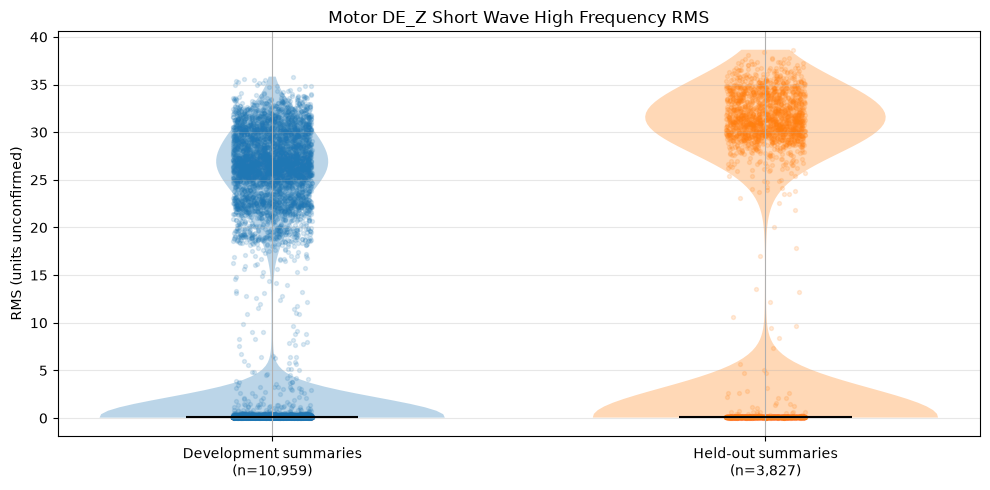

In [50]:
plot_rms_violin(
    [df_dev, df_hold_out],
    column=RMS_COL,
    labels=["Development summaries", "Held-out summaries"],
)


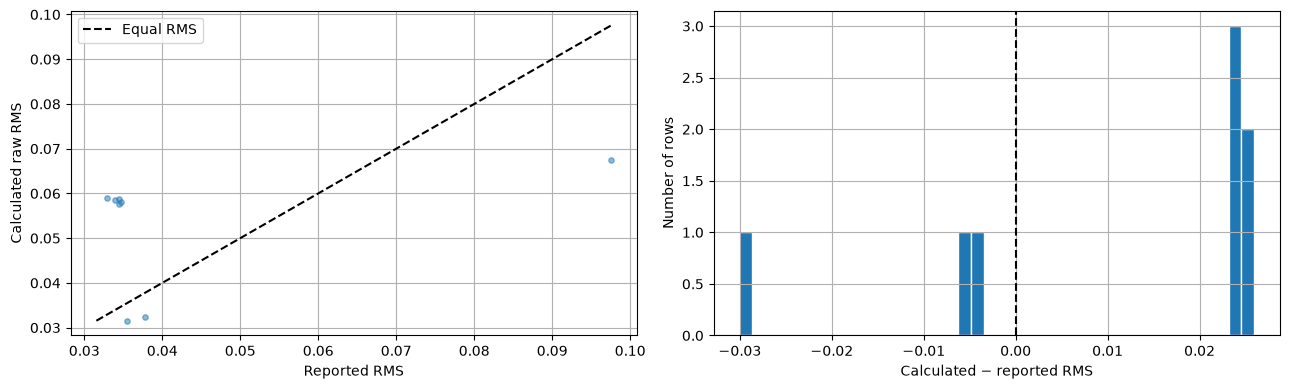

,value
paired_rows,8.000000
mean_difference,0.010271
difference_variance,0.000437
difference_std,0.020893
mean_absolute_difference,0.020084


,row_index,reported_rms,calculated_rms,difference
0,2656,0.03465,0.058046,0.023396
1,3959,0.03772,0.032478,-0.005242
2,4446,0.03443,0.057672,0.023242
3,5206,0.09757,0.067516,-0.030054
4,5527,0.03550,0.031545,-0.003955


In [51]:
# Paired comparisons require all record types, not summary-only records.
comparison, summary = compare_reported_calculated_rms(df_dev_all)
display(comparison.head())


In [52]:
df_rms = df_dev[RMS_COL]


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def find_rms_cutoff(series):
    values = pd.to_numeric(series, errors="coerce").to_numpy(
        dtype=float, na_value=np.nan
    )
    values = values[np.isfinite(values)]

    if np.unique(values).size < 2:
        raise ValueError("Need at least two distinct RMS values.")

    model = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20,
    ).fit(values.reshape(-1, 1))

    centres = np.sort(model.cluster_centers_.ravel())
    cutoff = float(centres.mean())

    print(f"Low cluster centre:  {centres[0]:.4f}")
    print(f"High cluster centre: {centres[1]:.4f}")
    print(f"Cutoff:              {cutoff:.4f}")

    plt.figure(figsize=(10, 4))
    plt.hist(values, bins=60, edgecolor="white")
    plt.axvline(
        cutoff, color="red", linestyle="--",
        label=f"Cutoff = {cutoff:.4f}",
    )
    plt.xlabel("High-frequency Z RMS (units unconfirmed)")
    plt.ylabel("Number of readings")
    plt.title("Development summary-record RMS cutoff")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return cutoff

Low cluster centre:  0.1932
High cluster centre: 26.5390
Cutoff:              13.3661


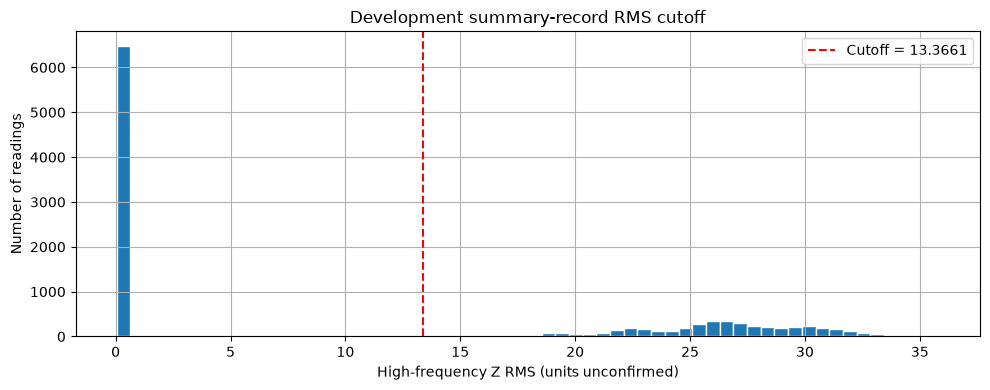

In [54]:
column = RMS_COL
cutoff = find_rms_cutoff(df_dev[column])


In [55]:
def find_active_periods(df, cutoff, max_gap="2h"):
    rms_col = RMS_COL
    gap_limit = pd.Timedelta(max_gap)

    if gap_limit <= pd.Timedelta(0):
        raise ValueError("max_gap must be positive.")

    data = df[["date", rms_col]].copy()
    data["date"] = pd.to_datetime(data["date"], utc=True, errors="coerce")
    data["rms"] = pd.to_numeric(data[rms_col], errors="coerce")

    valid = (
        data["date"].notna()
        & data["rms"].notna()
        & np.isfinite(data["rms"])
    )
    data = data.loc[valid].sort_values("date").reset_index(drop=True)

    if data["date"].duplicated().any():
        raise ValueError("Resolve duplicate timestamps before finding periods.")

    data["active"] = data["rms"] >= cutoff

    # Start a new period after inactivity or a substantial observation gap.
    new_period = data["active"] & (
        ~data["active"].shift(fill_value=False)
        | (data["date"].diff() > gap_limit)
    )

    data["run_id"] = (
        new_period.cumsum().where(data["active"]).astype("Int64")
    )

    periods = (
        data.loc[data["active"]]
        .groupby("run_id")
        .agg(
            first_active=("date", "min"),
            last_active=("date", "max"),
            readings=("date", "size"),
            median_rms=("rms", "median"),
        )
    )

    periods["observed_span_hours"] = (
        (periods["last_active"] - periods["first_active"])
        .dt.total_seconds() / 3600
    )

    fig, ax = plt.subplots(figsize=(15, 4))

    for active, label, colour in [
        (False, "Low vibration", "grey"),
        (True, "Likely active", "tab:orange"),
    ]:
        subset = data.loc[data["active"] == active]
        ax.scatter(
            subset["date"], subset["rms"],
            s=10, alpha=0.6, color=colour, label=label,
        )

    ax.axhline(
        cutoff, color="red", linestyle="--",
        label=f"Cutoff = {cutoff:.3f}",
    )

    for row in periods.itertuples():
        ax.axvspan(
            row.first_active, row.last_active,
            color="orange", alpha=0.1,
        )

    ax.set_title("Likely active periods from summary high-frequency Z RMS")
    ax.set_xlabel("Date (UTC)")
    ax.set_ylabel("RMS (units unconfirmed)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    display(periods.round(3))
    return data, periods

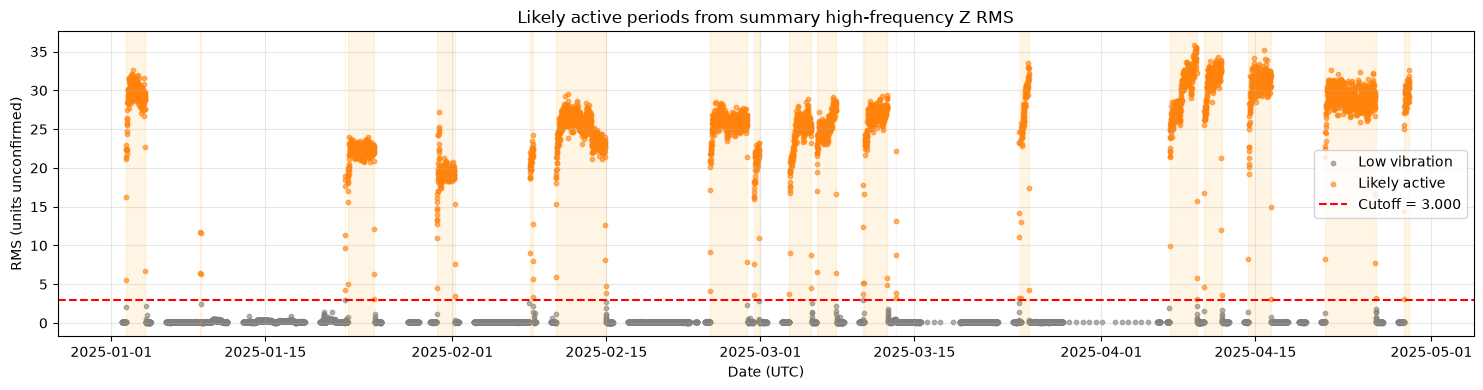

/var/folders/68/3qp_nqbs50dg_xn4rm7k1cz40000gn/T/ipykernel_31948/2682452077.py:81: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(periods.round(3))


,first_active,last_active,readings,median_rms,observed_span_hours
run_id,,,,,
1,2025-01-02 08:01:20+00:00,2025-01-04 02:21:20+00:00,244,29.705,42.333
2,2025-01-09 02:11:20+00:00,2025-01-09 02:41:20+00:00,4,8.971,0.500
3,2025-01-22 05:41:20+00:00,2025-01-22 06:41:20+00:00,6,14.519,1.000
4,2025-01-22 11:41:20+00:00,2025-01-24 21:51:20+00:00,328,22.277,58.167
5,2025-01-30 13:41:20+00:00,2025-02-01 05:01:20+00:00,225,19.222,39.333
6,2025-02-08 00:21:20+00:00,2025-02-08 08:31:20+00:00,48,21.178,8.167
7,2025-02-10 09:41:20+00:00,2025-02-14 22:21:20+00:00,621,25.451,108.667
8,2025-02-24 09:41:20+00:00,2025-02-27 19:41:20+00:00,453,25.947,82.000
9,2025-02-28 09:31:20+00:00,2025-02-28 21:21:20+00:00,69,21.324,11.833


In [60]:
active_readings, active_periods = find_active_periods(
    df_dev,
    cutoff=3,
    max_gap="4h",
)

In [61]:
run_stats = (
    active_readings.loc[active_readings["active"]]
    .groupby("run_id")["rms"]
    .describe(percentiles=[0.05, 0.50, 0.95])
    [["count", "mean", "std", "min", "5%", "50%", "95%", "max"]]
)

display(run_stats.round(3))

,count,mean,std,min,5%,50%,95%,max
run_id,,,,,,,,
1,244.0,29.166,2.956,5.540,24.439,29.705,31.594,32.606
2,4.0,9.016,3.049,6.364,6.368,8.971,11.729,11.760
3,6.0,13.391,5.946,4.229,5.586,14.519,18.864,19.016
4,328.0,21.944,1.997,3.041,20.023,22.277,23.324,24.052
5,225.0,19.068,2.388,3.445,15.738,19.222,21.277,27.152
6,48.0,19.755,4.417,3.298,8.386,21.178,22.913,24.263
7,621.0,24.986,2.486,3.840,22.111,25.451,27.573,29.493
8,453.0,25.714,1.977,4.134,23.395,25.947,27.452,28.482
9,69.0,20.304,3.317,3.594,16.082,21.324,22.825,23.210


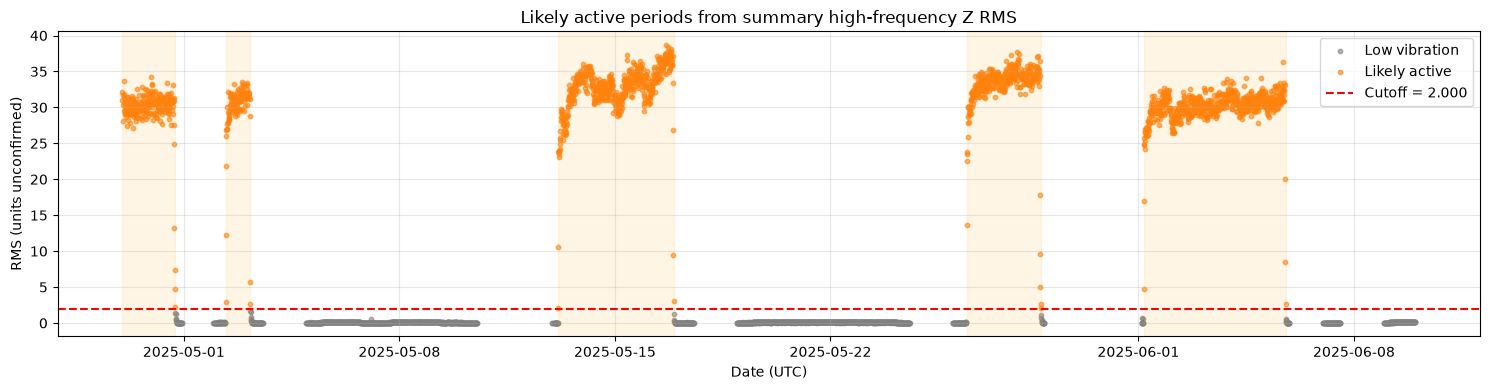

/var/folders/68/3qp_nqbs50dg_xn4rm7k1cz40000gn/T/ipykernel_31948/2682452077.py:81: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(periods.round(3))


,first_active,last_active,readings,median_rms,observed_span_hours
run_id,,,,,
1,2025-04-29 00:01:20+00:00,2025-04-30 17:11:20+00:00,223,30.218,41.167
2,2025-05-02 08:31:20+00:00,2025-05-03 03:41:20+00:00,109,30.935,19.167
3,2025-05-13 03:41:20+00:00,2025-05-16 21:41:20+00:00,515,33.213,90.000
4,2025-05-26 10:11:20+00:00,2025-05-28 20:01:20+00:00,333,33.924,57.833
5,2025-06-01 04:01:20+00:00,2025-06-05 18:41:20+00:00,636,30.290,110.667


In [59]:
active_readings, active_periods = find_active_periods(
    df_hold_out,
    cutoff=2,
    max_gap="2h",
)